# HVQC across MedMNIST — one hand-built quantum ansatz, six diseases, six imaging modalities
**Hybrid Variational Quantum Classifier · 8 qubits · Qiskit Aer / FakeSherbrooke / (optional) real IBM hardware**

The single-disease project (PneumoniaMNIST) is extended into a **benchmark across six MedMNIST datasets**, each turned into a *disease vs. reference* binary task so that the same circuit, the same readout and the same pipeline are used everywhere:

| # | Dataset | Disease task (class 1 = disease) | Modality |
|---|---|---|---|
| 1 | PneumoniaMNIST | pneumonia vs normal | chest X-ray |
| 2 | BreastMNIST | malignant vs normal/benign | breast ultrasound |
| 3 | DermaMNIST | melanoma vs melanocytic nevi | dermoscopy (RGB) |
| 4 | OCTMNIST | any retinal disease (CNV, DME, drusen) vs normal | retinal OCT |
| 5 | RetinaMNIST | diabetic retinopathy (grade 2-4) vs none (grade 0; grade 1 dropped as ambiguous) | fundus (RGB) |
| 6 | PathMNIST | colorectal adenocarcinoma vs normal mucosa | histology (RGB) |

**Research question (extended):** does a manually constructed, fully justified 8-qubit variational circuit stay competitive with auto-generated templates and with classical controls *across diseases and modalities*, rather than on one lucky dataset?

Everything from the single-dataset notebook is kept (PCA fit on train only -> 2x4 -> trainable CNN -> `pi*sigmoid` -> RY encoding -> manual "Converging-Cascade" ansatz -> Z on q4; fast-simulator equivalence proofs; real parameter-shift run; ablations; baselines; FakeSherbrooke), and Sections 2, 8-13 now loop over the six datasets.

| Section | What it does |
|---|---|
| 1-2 | Config; **six datasets -> binary tasks**, per-dataset PCA and splits |
| 3-5 | Ansatz library, fast simulator + equivalence proofs, ansatz verification (dataset-independent) |
| 6-7 | Hybrid training loop; real parameter-shift training (headline run on dataset 1) |
| 8 | Every ansatz on every dataset, multi-seed; PCA-vs-CNN ablation |
| 9 | Classical controls on every dataset |
| 10 | Shots; FakeSherbrooke noise per dataset |
| 11 | Optional IBM hardware run |
| 12 | Cross-dataset benchmark: tables, win/tie/loss, significance, figures, auto-generated results text |
| 13 | Reviewer checklist and limits |

**Read this first:** 28x28 images and 8 PCA components are a *harsh* bottleneck for some tasks (melanoma, retinopathy). Low accuracy there is a property of the input compression and the tiny scale, not necessarily of the circuit — the classical controls tell you which.

## 1. Setup and configuration

In [1]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime medmnist pylatexenc pandas -q

In [2]:
import time, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

import torch, torch.nn as nn, torch.nn.functional as F

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes, efficient_su2
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke

import medmnist
from medmnist import INFO

from google.colab import userdata
IBM_Token=userdata.get('IBM_Token')

N_QUBITS = 8
SHIFT = np.pi / 2

In [3]:
# ------------------------------- CONFIG -------------------------------
QUICK = False            # True = tiny smoke-test settings; False = the real study
ONLY = None              # e.g. ["pneumoniamnist", "dermamnist"] to run a subset of datasets

if QUICK:
    SEEDS, N_TRAIN, N_TEST, EPOCHS, LR = [0, 1], 60, 40, 12, 0.01
    N_PS_TRAIN, N_PS_EPOCHS, N_NOISY, SHOTS_LIST = 40, 6, 20, [200, 4000]
else:
    SEEDS, N_TRAIN, N_TEST, EPOCHS, LR = [0, 1, 2, 3, 4], 200, 200, 40, 0.02
    N_PS_TRAIN, N_PS_EPOCHS, N_NOISY, SHOTS_LIST = 60, 12, 30, [100, 500, 1000, 4000, 8000]

PCA_LR = 0.1             # larger step for the CNN-free PCA ablation: only 16 parameters train, so LR=0.02 would leave it undertrained
SHOTS_NOISY = 4000       # shots for FakeSherbrooke / hardware
RUN_NOISE = True         # FakeSherbrooke preview on every dataset (slowest part after training)
RUN_HARDWARE = True     # needs an IBM key (Section 11)

N_HARDWARE = 20
print("seeds", SEEDS, "| N_TRAIN", N_TRAIN, "| N_TEST", N_TEST, "| epochs", EPOCHS, "| lr", LR)

seeds [0, 1, 2, 3, 4] | N_TRAIN 200 | N_TEST 200 | epochs 40 | lr 0.02


## 2. Six datasets -> six disease-vs-reference binary tasks (Objectives 1 and 2)
* Each MedMNIST set is filtered to the classes named in `TASKS` and relabelled: **1 = disease, 0 = reference**. Label *names* are matched by keyword and printed, so you can see exactly which original classes went where (and an assertion stops the run if a keyword matches nothing).
* Class-balanced random subsets of the real train / test splits per seed. Small sets (BreastMNIST test has few malignant cases) simply give a smaller balanced test set.
* **PCA is fit on the training subset only**, separately for each dataset and seed. RGB datasets are flattened to 2352 values; grayscale to 784.
* Same CNN / `pi*sigmoid` angle encoding as before; `feature="pca"` remains the CNN-free ablation.
* **Choices that are mine, not MedMNIST's:** melanoma-vs-nevus, grade 0 vs grades 2-4 (grade 1 dropped), tumour epithelium vs normal mucosa, any-OCT-disease vs normal. Say so in the write-up; BloodMNIST is not used because blood-cell *types* are not diseases.

loaded pneumoniamnist
loaded breastmnist
loaded dermamnist
loaded octmnist
loaded retinamnist
loaded pathmnist


,dataset,modality,disease_classes,reference_classes,input_dim,train_ref_dis,test_ref_dis
0,Pneumonia,chest X-ray,pneumonia,normal,784,"(1214, 3494)","(234, 390)"
1,Breast cancer,breast ultrasound,malignant,"normal, benign",784,"(399, 147)","(114, 42)"
2,Melanoma,dermoscopy (RGB),melanoma,melanocytic nevi,2352,"(4693, 779)","(1341, 223)"
3,Retinal OCT disease,retinal OCT,choroidal neovascularization; diabetic macular...,normal,784,"(46026, 51451)","(250, 750)"
4,Diabetic retinopathy,fundus (RGB),2; 3; 4,0,2352,"(486, 466)","(174, 180)"
5,Colorectal cancer,histology (RGB),colorectal adenocarcinoma epithelium,normal colon mucosa,2352,"(7886, 12885)","(741, 1233)"


Pneumonia               0.726
Breast cancer           0.752
Melanoma                0.803
Retinal OCT disease     0.809
Diabetic retinopathy    0.920
Colorectal cancer       0.455


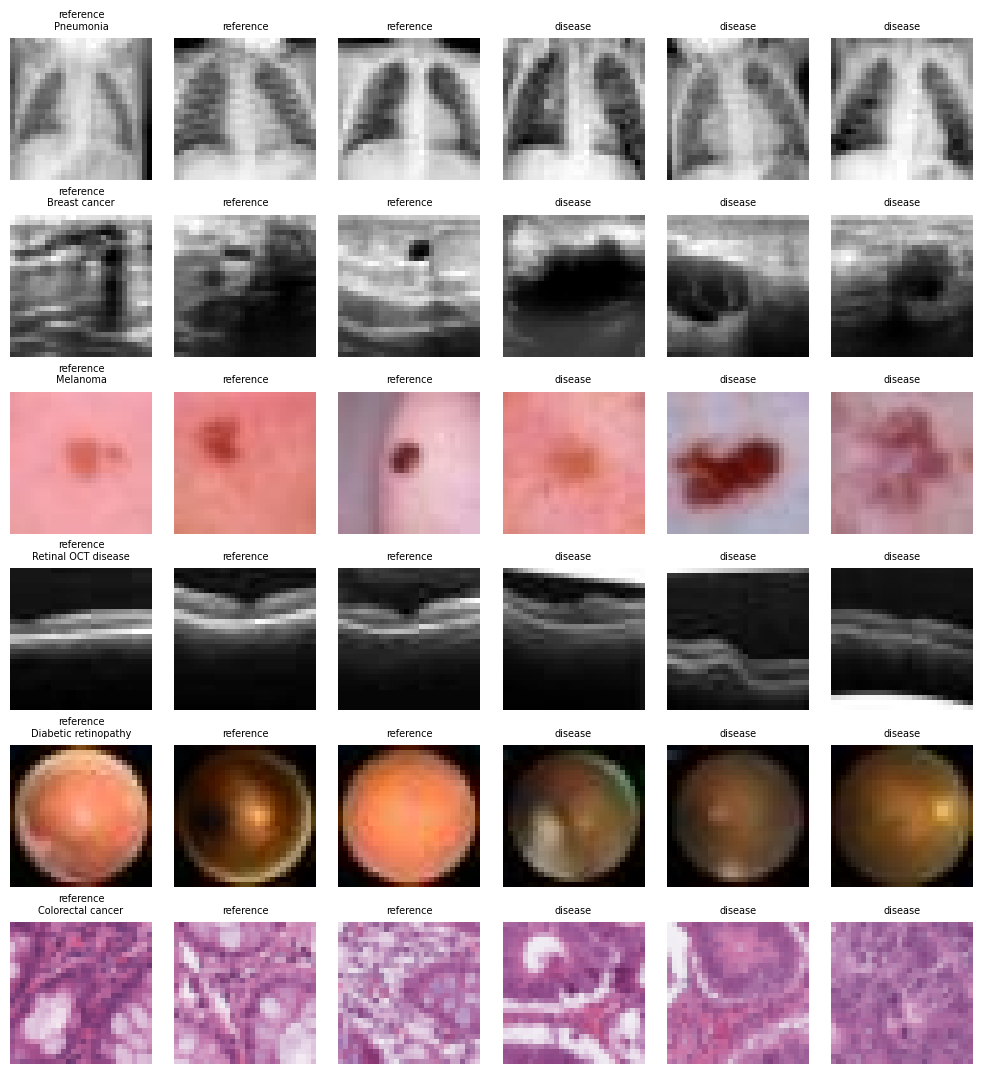

In [4]:
TASKS = [   # flag, name, modality, disease keywords (class 1), reference keywords (class 0)
    dict(flag="pneumoniamnist", name="Pneumonia",            modality="chest X-ray",       pos=["pneumonia"],                          neg=["normal"]),
    dict(flag="breastmnist",    name="Breast cancer",        modality="breast ultrasound", pos=["malignant"],                          neg=["normal", "benign"]),
    dict(flag="dermamnist",     name="Melanoma",             modality="dermoscopy (RGB)",  pos=["melanoma"],                           neg=["melanocytic nevi"]),
    dict(flag="octmnist",       name="Retinal OCT disease",  modality="retinal OCT",       pos=["choroidal", "macular", "drusen"],     neg=["normal"]),
    dict(flag="retinamnist",    name="Diabetic retinopathy", modality="fundus (RGB)",      pos=["2", "3", "4"],                        neg=["0"]),
    dict(flag="pathmnist",      name="Colorectal cancer",    modality="histology (RGB)",   pos=["adenocarcinoma"],                     neg=["normal colon"]),
]
if ONLY: TASKS = [t for t in TASKS if t["flag"] in ONLY]

def _matches(label, kw):
    label = label.strip().lower()
    return label.startswith(kw) if kw.isdigit() else kw in label

def load_task(task):
    info = INFO[task["flag"]]; Cls = getattr(medmnist, info["python_class"])
    names = {int(k): v for k, v in info["label"].items()}
    pos = [k for k, v in names.items() if any(_matches(v, w) for w in task["pos"])]
    neg = [k for k, v in names.items() if any(_matches(v, w) for w in task["neg"]) and k not in pos]
    assert pos and neg, f"{task['flag']}: label keywords matched nothing. Labels are: {names}"
    d = dict(task, pos_ids=pos, neg_ids=neg, names=names)
    for split in ("train", "test"):
        ds = Cls(split=split, download=True, size=28)
        imgs = np.asarray(ds.imgs); labels = np.asarray(ds.labels).reshape(-1)
        keep = np.isin(labels, pos + neg)
        d["img_shape"] = imgs.shape[1:]
        d["X" + split] = imgs[keep].reshape(int(keep.sum()), -1)
        d["y" + split] = np.isin(labels[keep], pos).astype(int)
    return d

DATA = {}
for t in TASKS:
    DATA[t["flag"]] = load_task(t); print("loaded", t["flag"], flush=True)

rows = []
for t in TASKS:
    D = DATA[t["flag"]]
    rows.append(dict(dataset=t["name"], modality=t["modality"], disease_classes="; ".join(D["names"][k] for k in D["pos_ids"]),
                     reference_classes="; ".join(D["names"][k] for k in D["neg_ids"]), input_dim=D["Xtrain"].shape[1],
                     train_ref_dis=tuple(np.bincount(D["ytrain"], minlength=2)), test_ref_dis=tuple(np.bincount(D["ytest"], minlength=2))))
display(pd.DataFrame(rows))

def balanced_idx(labels, n, rng):
    idx = []
    for c in np.unique(labels):
        pool = np.where(labels == c)[0]
        idx += rng.choice(pool, size=min(n // 2, len(pool)), replace=False).tolist()
    rng.shuffle(idx); return np.array(idx)

def make_split(seed, D):
    rng = np.random.default_rng(1000 + seed)
    tr = balanced_idx(D["ytrain"], N_TRAIN, rng); te = balanced_idx(D["ytest"], N_TEST, rng)
    Xtr = D["Xtrain"][tr] / 255.0; Xte = D["Xtest"][te] / 255.0
    pca = PCA(n_components=N_QUBITS).fit(Xtr)                     # train only
    Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)
    lo, hi = Ptr.min(0), Ptr.max(0)
    resc = lambda P: np.clip(np.pi * (P - lo) / (hi - lo + 1e-12), 0, np.pi)
    t = lambda P: torch.tensor(P, dtype=torch.float32).reshape(-1, 1, 2, 4)
    return dict(seed=seed, ytr=D["ytrain"][tr], yte=D["ytest"][te], pix_tr=Xtr, pix_te=Xte,
                pca_tr=Ptr, pca_te=Pte, img_tr=t(Ptr), img_te=t(Pte),
                ang_tr=torch.tensor(resc(Ptr)), ang_te=torch.tensor(resc(Pte)), evr=pca.explained_variance_ratio_)

SPLITS = {(t["flag"], s): make_split(s, DATA[t["flag"]]) for t in TASKS for s in SEEDS}
split0 = SPLITS[(TASKS[0]["flag"], SEEDS[0])]          # used by the headline parameter-shift run (Section 7)
print(pd.Series({t["name"]: round(float(SPLITS[(t["flag"], SEEDS[0])]["evr"].sum()), 3) for t in TASKS}, name="PCA variance kept by 8 components").to_string())

fig, ax = plt.subplots(len(TASKS), 6, figsize=(10, 1.8 * len(TASKS)))
ax = np.atleast_2d(ax)
for r, t in enumerate(TASKS):
    sp = SPLITS[(t["flag"], SEEDS[0])]; shp = DATA[t["flag"]]["img_shape"]
    for c in range(6):
        want = 0 if c < 3 else 1; i = np.where(sp["ytr"] == want)[0][c % 3]
        im = (sp["pix_tr"][i] * 255).reshape(shp).astype(np.uint8)
        ax[r, c].imshow(im, cmap="gray" if len(shp) == 2 else None); ax[r, c].axis("off")
        ax[r, c].set_title(("reference" if want == 0 else "disease") + (f"\n{t['name']}" if c == 0 else ""), fontsize=7)
plt.tight_layout(); plt.show()

In [5]:
class FeatureCNN(nn.Module):
    def __init__(self, n_out=N_QUBITS):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, 2, padding=1); self.conv2 = nn.Conv2d(8, 16, 2, padding=1)
        self.bn1 = nn.BatchNorm2d(8); self.bn2 = nn.BatchNorm2d(16)
        self.fc1 = nn.Linear(16 * 4 * 6, 64); self.fc2 = nn.Linear(64, n_out); self.drop = nn.Dropout(0.1)
    def forward(self, x):
        x = torch.relu(self.bn1(self.conv1(x))); x = torch.relu(self.bn2(self.conv2(x)))
        return self.fc2(self.drop(torch.relu(self.fc1(x.flatten(1)))))
print("CNN trainable parameters:", sum(p.numel() for p in FeatureCNN().parameters()))

CNN trainable parameters: 25776


## 3. The ansatz (Objective 3)
### The manual "Converging-Cascade" ansatz
```
 q0 ─RY(x0)─RY(θ)─■───────────────────────────────────────────
 q1 ─RY(x1)─RY(θ)─X─RY(θ)─■────────────────────────────────────
 q2 ─RY(x2)─RY(θ)─────────X─RY(θ)─■─────────────────────────────
 q3 ─RY(x3)─RY(θ)─────────────────X─RY(θ)─■─────────────────────
                                           │ merge
 q4 ─RY(x4)─RY(θ)─────────────────X─RY(θ)─X─RX(θ)─RY(θ)─ <Z>  ◄── the single readout qubit
 q5 ─RY(x5)─RY(θ)─────────X─RY(θ)─■─────────────────────────────
 q6 ─RY(x6)─RY(θ)─X─RY(θ)─■────────────────────────────────────
 q7 ─RY(x7)─RY(θ)─■───────────────────────────────────────────
```
(schematic — the exact circuit is drawn below.) One block = **16 parameters, 7 CNOTs**.

**Why each piece is there**
1. **A single, explicit readout qubit (q4)**, and every encoded feature is inside its light cone (verified in §5). The earlier notebooks' `"Z"+"I"*7` actually read q7 (Qiskit is little-endian).
2. **Two cascades converging on the middle**: 7 CNOTs is the minimum that connects 8 qubits (n-1); two half-chains plus a merge halve the two-qubit depth versus one long chain — vital under NISQ noise (§3.5).
3. **Nearest-neighbour CNOTs only** -> no SWAPs on line / heavy-hex hardware.
4. **Trainable gates are single-qubit rotations used once each** -> the π/2 parameter-shift rule is *exact*.
5. **RY (not RZ) first**: the data are encoded with RY, so the state is real. A leading RZ on a pure CNOT-control qubit commutes through and is a *dead* parameter (found numerically). RY after the CNOT acts on the target, where it does not commute, so every parameter is alive.
6. **RY after each CNOT makes the fixed Clifford entangler tunable** — a learnable mix of two features, the quantum analogue of a pooling weight (tree / QCNN-style circuit; shallow + local observable = barren-plateau friendly).
7. **Final RX -> RY on the readout qubit** = a free measurement axis (two angles cover the Bloch sphere).
8. **Entanglement is what makes it quantum** (§3.2): the product-state control in §8 uses the same single-qubit rotations *without* CNOTs.

**Comparison ansätze** (same encoding, same readout rule as the earlier notebooks): `real_amplitudes` (reps=2, linear, 24 params) and `efficient_su2` (reps=2, linear, 48 params), both read out on q7; plus the **product-state control** (no CNOTs, 16 params, mean of `<Z>` over all qubits so it can see every feature).

design                     params  CNOTs    param-shift runs / sample / step
manual (1 block)               16      7                                  48
manual (2 blocks)              32     14                                  80
manual (3 blocks)              48     21                                 112
real_amplitudes r2             24     14                                  64
efficient_su2 r2               48     14                                 112
product-state (no CNOT)        16      0                                  48


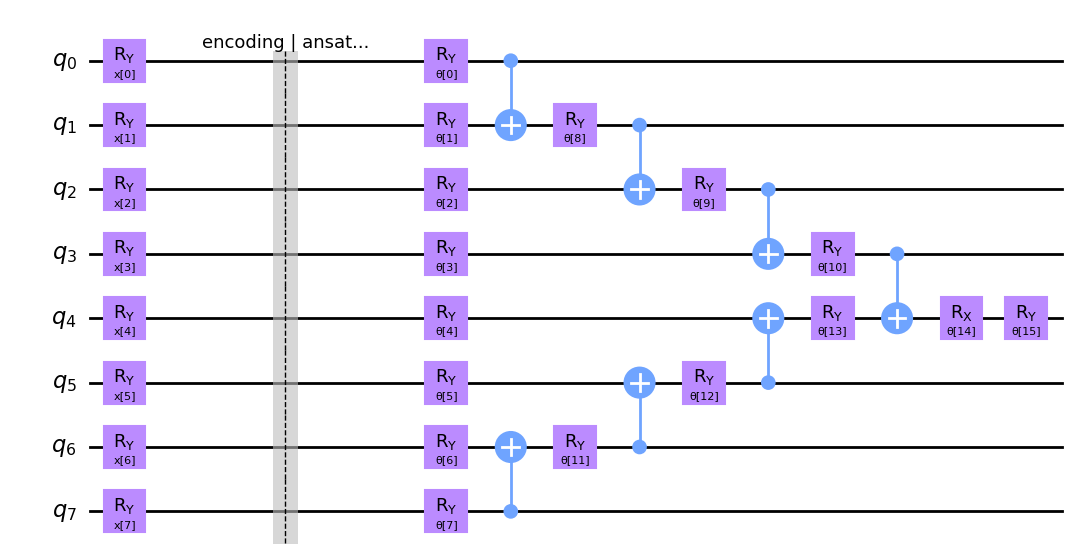

In [6]:
# An ansatz is a list of ops: ("rx"|"ry"|"rz", qubit) consumes the next parameter; ("cx", control, target) is fixed.
LEFT_CASCADE  = [(0, 1), (1, 2), (2, 3)]
RIGHT_CASCADE = [(7, 6), (6, 5), (5, 4)]
MERGE = (3, 4)
READOUT_QUBIT = 4

def manual_spec(blocks=1):
    ops = []
    for _ in range(blocks):
        ops += [("ry", q) for q in range(N_QUBITS)]
        for c, t in LEFT_CASCADE + RIGHT_CASCADE: ops += [("cx", c, t), ("ry", t)]
        ops += [("cx", *MERGE), ("rx", MERGE[1]), ("ry", MERGE[1])]
    return ops

def library_spec(kind, reps=2):            # mirrors qiskit's real_amplitudes / efficient_su2 (linear)
    ops = []
    for r in range(reps + 1):
        for q in range(N_QUBITS): ops.append(("ry", q))
        if kind == "su2":
            for q in range(N_QUBITS): ops.append(("rz", q))
        if r < reps: ops += [("cx", i, i + 1) for i in range(N_QUBITS - 1)]
    return ops

def product_spec():                    # NO entanglement: independent single-qubit rotations, 16 params
    return [(g, q) for g in ("ry", "rx") for q in range(N_QUBITS)]

def n_params(ops): return sum(o[0] != "cx" for o in ops)
def n_cx(ops): return sum(o[0] == "cx" for o in ops)

ALL_QUBITS = list(range(N_QUBITS))
DESIGNS = {   # name -> (ops, readout qubits)
    "manual (1 block)":      (manual_spec(1), [READOUT_QUBIT]),
    "manual (2 blocks)":     (manual_spec(2), [READOUT_QUBIT]),
    "manual (3 blocks)":     (manual_spec(3), [READOUT_QUBIT]),
    "real_amplitudes r2":    (library_spec("ra"), [7]),
    "efficient_su2 r2":      (library_spec("su2"), [7]),
    "product-state (no CNOT)": (product_spec(), ALL_QUBITS),
}

def build_circuit(ops):
    qc = QuantumCircuit(N_QUBITS); x = ParameterVector("x", N_QUBITS)
    for q in range(N_QUBITS): qc.ry(x[q], q)
    qc.barrier(label="encoding | ansatz")
    th = ParameterVector("θ", n_params(ops))   # "θ" sorts after "x": binding order is [x..., θ...]
    k = 0
    for o in ops:
        if o[0] == "cx": qc.cx(o[1], o[2])
        else: getattr(qc, o[0])(th[k], o[1]); k += 1
    assert [p.name for p in qc.parameters][:N_QUBITS] == [f"x[{i}]" for i in range(N_QUBITS)]
    return qc

def build_observable(readout):
    return SparsePauliOp.from_sparse_list([("Z", [q], 1.0 / len(readout)) for q in readout], num_qubits=N_QUBITS)

print(f"{'design':26s}{'params':>7s}{'CNOTs':>7s}{'param-shift runs / sample / step':>36s}")
for k, (ops, ro) in DESIGNS.items():
    print(f"{k:26s}{n_params(ops):7d}{n_cx(ops):7d}{2 * (n_params(ops) + N_QUBITS):36d}")
build_circuit(DESIGNS["manual (1 block)"][0]).draw("mpl", style="clifford", fold=-1)

## 4. Fast exact simulator, and proof that it equals Aer and the parameter-shift rule
A small batched PyTorch statevector simulator (8 qubits = 256 amplitudes). For ideal circuits whose trainable gates are `exp(-iθP/2)` used once, the shift-rule gradient is *identically* the analytic gradient, so `torch.autograd` through this simulator gives the same numbers as the 2-evaluations-per-parameter procedure — just ~1000x faster. Assertions below check that on this machine.

In [7]:
def _rot(kind, a):
    c, s = torch.cos(a / 2), torch.sin(a / 2); z = torch.zeros_like(c)
    if kind == "ry": return torch.stack([torch.stack([c, -s]), torch.stack([s, c])]).to(torch.complex128)
    if kind == "rx": return torch.stack([torch.stack([c + 0j, -1j * s]), torch.stack([-1j * s, c + 0j])])
    return torch.stack([torch.stack([torch.exp(-1j * a / 2), z + 0j]), torch.stack([z + 0j, torch.exp(1j * a / 2)])])

def _ax(q): return 1 + (N_QUBITS - 1 - q)            # Qiskit little-endian: qubit q <-> axis N-1-q

def _cx(psi, c, t):
    ac, at = _ax(c), _ax(t)
    idx = [slice(None)] * (N_QUBITS + 1); idx[ac] = 1
    sub = psi[tuple(idx)]; out = psi.clone()
    out[tuple(idx)] = torch.flip(sub, dims=[at - 1 if at > ac else at])
    return out

def sim_expectation(angles, theta, ops, readout):
    '''angles (B,8) float64, theta (P,) float64 -> mean <Z> over `readout` qubits, shape (B,). Differentiable.'''
    B = angles.shape[0]
    psi = torch.zeros((B,) + (2,) * N_QUBITS, dtype=torch.complex128); psi[(slice(None),) + (0,) * N_QUBITS] = 1
    for q in range(N_QUBITS):
        c, s = torch.cos(angles[:, q] / 2), torch.sin(angles[:, q] / 2)
        U = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)
        p = torch.movedim(psi, _ax(q), -1); p = torch.einsum("b...j,bij->b...i", p, U); psi = torch.movedim(p, -1, _ax(q))
    k = 0
    for o in ops:
        if o[0] == "cx": psi = _cx(psi, o[1], o[2])
        else:
            U = _rot(o[0], theta[k]); k += 1
            p = torch.movedim(psi, _ax(o[1]), -1) @ U.T; psi = torch.movedim(p, -1, _ax(o[1]))
    prob = psi.abs() ** 2; z = 0
    for q in readout:
        p0 = prob.movedim(_ax(q), 1).reshape(B, 2, -1).sum(-1); z = z + (p0[:, 0] - p0[:, 1])
    return z / len(readout)

# ---- equivalence checks on every design ----
rng = np.random.default_rng(0); est_chk = AerEstimator()
for name, (ops, ro) in DESIGNS.items():
    qc_, obs_ = build_circuit(ops), build_observable(ro); P = n_params(ops)
    A = rng.uniform(0.2, np.pi - 0.2, (3, N_QUBITS)); th = rng.uniform(0, 2 * np.pi, P)
    aer = np.array([r.data.evs for r in est_chk.run([(qc_, obs_, list(a) + list(th)) for a in A]).result()], float)
    mine = sim_expectation(torch.tensor(A), torch.tensor(th), ops, ro).numpy()
    t = torch.tensor(th, requires_grad=True); sim_expectation(torch.tensor(A), t, ops, ro).sum().backward()
    ps = []
    for j in range(P):
        tp, tm = th.copy(), th.copy(); tp[j] += SHIFT; tm[j] -= SHIFT
        ps.append((sim_expectation(torch.tensor(A), torch.tensor(tp), ops, ro) - sim_expectation(torch.tensor(A), torch.tensor(tm), ops, ro)).sum().item() / 2)
    e1, e2 = np.abs(aer - mine).max(), np.abs(np.array(ps) - t.grad.numpy()).max()
    print(f"{name:26s} |sim-Aer| = {e1:.1e}   |param-shift - autograd| = {e2:.1e}")
    assert e1 < 1e-9 and e2 < 1e-9

manual (1 block)           |sim-Aer| = 4.4e-16   |param-shift - autograd| = 6.4e-16
manual (2 blocks)          |sim-Aer| = 1.4e-16   |param-shift - autograd| = 6.7e-16
manual (3 blocks)          |sim-Aer| = 6.2e-17   |param-shift - autograd| = 5.0e-16
real_amplitudes r2         |sim-Aer| = 3.3e-16   |param-shift - autograd| = 7.1e-16
efficient_su2 r2           |sim-Aer| = 5.0e-16   |param-shift - autograd| = 5.3e-16
product-state (no CNOT)    |sim-Aer| = 5.6e-17   |param-shift - autograd| = 3.9e-16


## 5. Verifying the ansatz: light cone, dead parameters, barren-plateau check (§3.6 / Q10)
* **Light cone** — every encoded feature must influence the readout.
* **Dead parameters** — a parameter that never changes the output is wasted.
* **Gradient variance at initialisation** — variance across random initialisations; collapse towards 0 would be the barren-plateau signature. At 8 qubits it is expected to be healthy.

In [8]:
rng = np.random.default_rng(1)
Xp = torch.tensor(rng.uniform(0.2, np.pi - 0.2, (20, N_QUBITS)))
rows = []
for name, (ops, ro) in DESIGNS.items():
    P = n_params(ops)
    xx = Xp.clone().requires_grad_(True); th = torch.tensor(rng.uniform(0, 2 * np.pi, P))
    sim_expectation(xx, th, ops, ro).sum().backward(); lc = int((xx.grad.abs().sum(0) > 1e-9).sum())
    J = torch.autograd.functional.jacobian(lambda t: sim_expectation(Xp, t, ops, ro), th.clone().requires_grad_(True)).numpy()
    dead = int((np.abs(J).sum(0) < 1e-9).sum()); sv = np.linalg.svd(J, compute_uv=False); rank = int((sv > 1e-8 * sv[0]).sum())
    gs = []
    for _ in range(60):
        t = torch.tensor(rng.uniform(0, 2 * np.pi, P), requires_grad=True)
        sim_expectation(Xp, t, ops, ro).mean().backward(); gs.append(t.grad.numpy().copy())
    gv = np.array(gs).var(0)
    rows.append(dict(design=name, params=P, CNOTs=n_cx(ops), features_in_lightcone=f"{lc}/8", dead_params=dead,
                     effective_rank=f"{rank}/{P}", grad_var_mean=round(gv.mean(), 5), grad_var_min=round(gv.min(), 6)))
verif = pd.DataFrame(rows); display(verif)
print("Reading: gradient variance is non-vanishing for every design -> no barren-plateau signature at 8 qubits.")
print("effective_rank < params means some directions are redundant at that random point (information, not an error).")

,design,params,CNOTs,features_in_lightcone,dead_params,effective_rank,grad_var_mean,grad_var_min
0,manual (1 block),16,7,8/8,0,16/16,0.01664,0.000152
1,manual (2 blocks),32,14,8/8,0,20/32,0.00997,0.000140
2,manual (3 blocks),48,21,8/8,0,20/48,0.00631,0.000091
3,real_amplitudes r2,24,14,8/8,7,17/24,0.00715,0.000000
4,efficient_su2 r2,48,14,8/8,22,20/48,0.00235,0.000000
5,product-state (no CNOT),16,0,8/8,0,16/16,0.00209,0.001505


Reading: gradient variance is non-vanishing for every design -> no barren-plateau signature at 8 qubits.
effective_rank < params means some directions are redundant at that random point (information, not an error).


## 6. Hybrid training loop (Objective 4)
Adam updates the CNN weights **and** the ansatz parameters jointly; loss = binary cross-entropy on `p = (1 - <Z>)/2`; prediction = class 1 if `<Z> < 0`. Gradients flow back through the quantum layer exactly as the parameter-shift rule would deliver them (§4); the real shift-rule implementation is run in §7.

manual (1 block), seed 0: train acc 0.980 | test acc 0.785 | F1 0.796 | AUC 0.794 | 4.4s


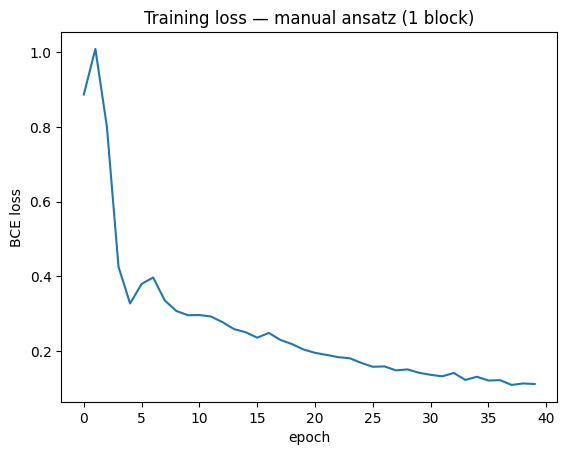

In [9]:
def metrics(y, z):
    pred = (np.asarray(z) < 0).astype(int)
    auc = roc_auc_score(y, -np.asarray(z)) if len(np.unique(y)) > 1 else float("nan")
    return dict(acc=accuracy_score(y, pred), f1=f1_score(y, pred), auc=auc)

def train_hybrid(ops, readout, split, seed, feature="cnn", epochs=None, lr=None, verbose=False):
    epochs = epochs or EPOCHS; lr = lr or LR
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    theta = nn.Parameter(torch.tensor(rng.uniform(0, 2 * np.pi, n_params(ops))))
    cnn = FeatureCNN() if feature == "cnn" else None
    opt = torch.optim.Adam(([theta] + list(cnn.parameters())) if cnn else [theta], lr=lr)
    ytr = torch.tensor(split["ytr"], dtype=torch.float64); hist = []
    for ep in range(epochs):
        if cnn: cnn.train()
        opt.zero_grad()
        ang = (np.pi * torch.sigmoid(cnn(split["img_tr"]))).double() if cnn else split["ang_tr"]
        z = sim_expectation(ang, theta, ops, readout)
        loss = F.binary_cross_entropy(((1 - z) / 2).clamp(1e-6, 1 - 1e-6), ytr); loss.backward(); opt.step()
        hist.append(loss.item())
        if verbose: print(f"epoch {ep + 1:3d} loss {loss.item():.4f}")
    if cnn: cnn.eval()
    with torch.no_grad():
        f = lambda img, a: (np.pi * torch.sigmoid(cnn(img))).double() if cnn else a
        ang_tr, ang_te = f(split["img_tr"], split["ang_tr"]), f(split["img_te"], split["ang_te"])
        z_tr = sim_expectation(ang_tr, theta, ops, readout).numpy(); z_te = sim_expectation(ang_te, theta, ops, readout).numpy()
        raw_tr = cnn(split["img_tr"]).numpy() if cnn else split["pca_tr"]; raw_te = cnn(split["img_te"]).numpy() if cnn else split["pca_te"]
    return dict(theta=theta.detach().numpy().copy(), cnn=cnn, hist=hist, z_te=z_te, ang_te=ang_te.numpy(),
                raw_tr=raw_tr, raw_te=raw_te, train=metrics(split["ytr"], z_tr), test=metrics(split["yte"], z_te))

t0 = time.time(); r = train_hybrid(*DESIGNS["manual (1 block)"], split0, seed=0, verbose=False)
print(f"manual (1 block), seed 0: train acc {r['train']['acc']:.3f} | test acc {r['test']['acc']:.3f} | F1 {r['test']['f1']:.3f} | AUC {r['test']['auc']:.3f} | {time.time() - t0:.1f}s")
plt.plot(r["hist"]); plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Training loss — manual ansatz (1 block)"); plt.show()

## 7. The headline run with the *real* parameter-shift rule on Aer
The same procedure as the first-review notebooks (2 circuit evaluations per parameter, for the ansatz parameters **and** the 8 encoding angles, through a custom `torch.autograd.Function`), applied to the manual ansatz. The loss curve is then compared with the fast-simulator run on identical data/seed — they must coincide.

  [parameter-shift] epoch  1/12 loss 0.8164
  [parameter-shift] epoch  2/12 loss 0.6213
  [parameter-shift] epoch  3/12 loss 0.4415
  [parameter-shift] epoch  4/12 loss 0.3789
  [parameter-shift] epoch  5/12 loss 0.3387
  [parameter-shift] epoch  6/12 loss 0.2702
  [parameter-shift] epoch  7/12 loss 0.2386
  [parameter-shift] epoch  8/12 loss 0.2053
  [parameter-shift] epoch  9/12 loss 0.1922
  [parameter-shift] epoch 10/12 loss 0.1681
  [parameter-shift] epoch 11/12 loss 0.1302
  [parameter-shift] epoch 12/12 loss 0.1154
parameter-shift run: 108s | test acc 0.635 F1 0.716 AUC 0.819
max |loss(fast simulator) - loss(parameter-shift)| over 12 epochs = 9.33e-08


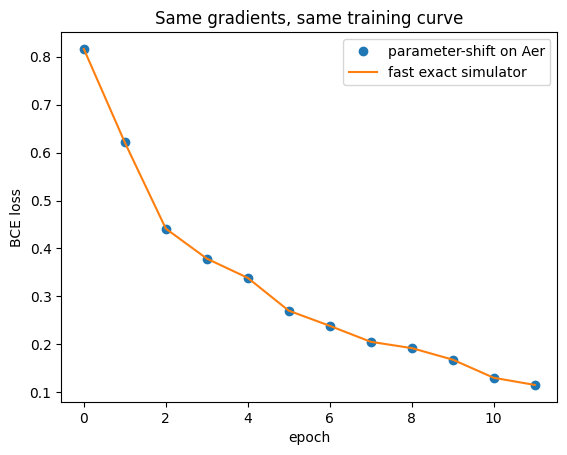

In [10]:
class PSCircuit:
    def __init__(self, ops, readout):
        self.ops, self.P = ops, n_params(ops); self.qc = build_circuit(ops); self.obs = build_observable(readout); self.est = AerEstimator()
    def expect(self, A, th):
        res = self.est.run([(self.qc, self.obs, list(a) + list(th)) for a in A]).result()
        return np.array([r.data.evs for r in res], dtype=np.float64)
    def backward(self, A, th, g):
        B = A.shape[0]; pubs = []
        for j in range(self.P):
            for s in (+SHIFT, -SHIFT):
                t2 = th.copy(); t2[j] += s; pubs += [(self.qc, self.obs, list(a) + list(t2)) for a in A]
        for i in range(N_QUBITS):
            for s in (+SHIFT, -SHIFT):
                for a in A:
                    a2 = a.copy(); a2[i] += s; pubs.append((self.qc, self.obs, list(a2) + list(th)))
        v = np.array([r.data.evs for r in self.est.run(pubs).result()], dtype=np.float64); k = 0
        gt = np.zeros(self.P); ga = np.zeros((B, N_QUBITS))
        for j in range(self.P):
            zp, zm = v[k:k + B], v[k + B:k + 2 * B]; k += 2 * B; gt[j] = np.sum(g * (zp - zm) / 2)
        for i in range(N_QUBITS):
            zp, zm = v[k:k + B], v[k + B:k + 2 * B]; k += 2 * B; ga[:, i] = g * (zp - zm) / 2
        return ga, gt

class QuantumExpectation(torch.autograd.Function):
    @staticmethod
    def forward(ctx, angles, theta, circ):
        ctx.circ, ctx.A, ctx.th = circ, angles.detach().numpy().astype(np.float64), theta.detach().numpy().astype(np.float64)
        return torch.tensor(circ.expect(ctx.A, ctx.th), dtype=torch.float32)
    @staticmethod
    def backward(ctx, go):
        ga, gt = ctx.circ.backward(ctx.A, ctx.th, go.detach().numpy().astype(np.float64))
        return torch.tensor(ga, dtype=torch.float32), torch.tensor(gt, dtype=torch.float32), None

def train_parameter_shift(ops, readout, split, seed, n_train, epochs, lr):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    circ = PSCircuit(ops, readout)
    theta = nn.Parameter(torch.tensor(rng.uniform(0, 2 * np.pi, circ.P), dtype=torch.float32)); cnn = FeatureCNN()
    opt = torch.optim.Adam(list(cnn.parameters()) + [theta], lr=lr)
    img, y = split["img_tr"][:n_train], torch.tensor(split["ytr"][:n_train], dtype=torch.float32); hist = []
    for ep in range(epochs):
        cnn.train(); opt.zero_grad()
        z = QuantumExpectation.apply(np.pi * torch.sigmoid(cnn(img)), theta, circ)
        loss = F.binary_cross_entropy(((1 - z) / 2).clamp(1e-6, 1 - 1e-6), y); loss.backward(); opt.step(); hist.append(loss.item())
        print(f"  [parameter-shift] epoch {ep + 1:2d}/{epochs} loss {loss.item():.4f}")
    cnn.eval()
    with torch.no_grad(): ang_te = (np.pi * torch.sigmoid(cnn(split["img_te"]))).numpy().astype(np.float64)
    z_te = circ.expect(ang_te, theta.detach().numpy().astype(np.float64))
    return dict(hist=hist, test=metrics(split["yte"], z_te), cnn=cnn, theta=theta.detach().numpy().astype(np.float64), ang_te=ang_te, z_te=z_te)

ops1, ro1 = DESIGNS["manual (1 block)"]
t0 = time.time(); ps_run = train_parameter_shift(ops1, ro1, split0, 0, N_PS_TRAIN, N_PS_EPOCHS, 0.01)
print(f"parameter-shift run: {time.time() - t0:.0f}s | test acc {ps_run['test']['acc']:.3f} F1 {ps_run['test']['f1']:.3f} AUC {ps_run['test']['auc']:.3f}")

# same data / seed / config through the fast exact simulator
sub = {**split0, "img_tr": split0["img_tr"][:N_PS_TRAIN], "ytr": split0["ytr"][:N_PS_TRAIN]}
fast = train_hybrid(ops1, ro1, sub, 0, epochs=N_PS_EPOCHS, lr=0.01)
diff = np.max(np.abs(np.array(fast["hist"]) - np.array(ps_run["hist"])))
print(f"max |loss(fast simulator) - loss(parameter-shift)| over {N_PS_EPOCHS} epochs = {diff:.2e}")
assert diff < 5e-3, "fast simulator and parameter-shift training disagree"
plt.plot(ps_run["hist"], "o", label="parameter-shift on Aer"); plt.plot(fast["hist"], "-", label="fast exact simulator")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Same gradients, same training curve"); plt.show()

## 8. Every ansatz on every dataset (success criteria, Q4, Q7)
Each row of the tables is mean ± std over `SEEDS` (different balanced subsets, PCA fits, CNN inits and θ inits), for **each of the six datasets**.
* **8a-c** ansatz comparison, entanglement ablation, depth 1 / 2 / 3 blocks — all on every dataset.
* **8d** trainable CNN vs plain PCA features (manual ansatz). The PCA-only variant trains just the 16 circuit parameters, so it uses a larger learning rate (`PCA_LR`) to avoid being unfairly undertrained.
Differences under about one std are not evidence of a gap; Section 12 aggregates across datasets.

In [11]:
RUNS = {}
def run_grid(names, feature="cnn"):
    out = []
    for t in TASKS:
        for name in names:
            ops, ro = DESIGNS[name]
            for s in SEEDS:
                sp = SPLITS[(t["flag"], s)]; t0 = time.time(); r = train_hybrid(ops, ro, sp, s, feature=feature, lr=(PCA_LR if feature == "pca" else None))
                out.append(dict(dataset=t["name"], design=name, feature=feature, seed=s, params=n_params(ops), cnots=n_cx(ops),
                                train_acc=r["train"]["acc"], acc=r["test"]["acc"], f1=r["test"]["f1"], auc=r["test"]["auc"],
                                final_loss=r["hist"][-1], secs=time.time() - t0))
                RUNS[(t["flag"], name, feature, s)] = r
        print("done", t["name"], feature, flush=True)
    return pd.DataFrame(out)

def pivot(df, col="acc"):
    g = df.groupby(["dataset", "design"], sort=False)[col].agg(["mean", "std"])
    return (g["mean"].round(3).astype(str) + " ± " + g["std"].fillna(0).round(3).astype(str)).unstack("design")[list(dict.fromkeys(df.design))].loc[[t["name"] for t in TASKS]]

In [12]:
df_main = run_grid(list(DESIGNS.keys()), feature="cnn")
print("TEST ACCURACY (mean ± std over seeds)"); display(pivot(df_main, "acc"))
print("TEST AUC (mean ± std over seeds)"); display(pivot(df_main, "auc"))

done Pneumonia cnn
done Breast cancer cnn
done Melanoma cnn
done Retinal OCT disease cnn
done Diabetic retinopathy cnn
done Colorectal cancer cnn
TEST ACCURACY (mean ± std over seeds)


design,manual (1 block),manual (2 blocks),manual (3 blocks),real_amplitudes r2,efficient_su2 r2,product-state (no CNOT)
dataset,,,,,,
Pneumonia,0.805 ± 0.019,0.803 ± 0.043,0.805 ± 0.036,0.808 ± 0.029,0.813 ± 0.05,0.806 ± 0.029
Breast cancer,0.71 ± 0.034,0.701 ± 0.044,0.693 ± 0.034,0.589 ± 0.166,0.706 ± 0.054,0.654 ± 0.043
Melanoma,0.709 ± 0.035,0.71 ± 0.028,0.703 ± 0.017,0.677 ± 0.1,0.719 ± 0.028,0.717 ± 0.045
Retinal OCT disease,0.626 ± 0.048,0.59 ± 0.064,0.606 ± 0.072,0.582 ± 0.052,0.625 ± 0.077,0.618 ± 0.053
Diabetic retinopathy,0.76 ± 0.017,0.74 ± 0.025,0.748 ± 0.047,0.705 ± 0.121,0.753 ± 0.044,0.743 ± 0.051
Colorectal cancer,0.641 ± 0.04,0.624 ± 0.034,0.617 ± 0.07,0.576 ± 0.055,0.655 ± 0.081,0.621 ± 0.065


TEST AUC (mean ± std over seeds)


design,manual (1 block),manual (2 blocks),manual (3 blocks),real_amplitudes r2,efficient_su2 r2,product-state (no CNOT)
dataset,,,,,,
Pneumonia,0.863 ± 0.044,0.861 ± 0.035,0.861 ± 0.023,0.869 ± 0.031,0.881 ± 0.012,0.874 ± 0.02
Breast cancer,0.727 ± 0.026,0.726 ± 0.045,0.709 ± 0.044,0.677 ± 0.071,0.719 ± 0.016,0.705 ± 0.04
Melanoma,0.78 ± 0.028,0.769 ± 0.014,0.755 ± 0.041,0.723 ± 0.128,0.766 ± 0.017,0.776 ± 0.024
Retinal OCT disease,0.651 ± 0.038,0.595 ± 0.073,0.659 ± 0.051,0.6 ± 0.067,0.617 ± 0.095,0.637 ± 0.069
Diabetic retinopathy,0.776 ± 0.043,0.772 ± 0.028,0.782 ± 0.03,0.678 ± 0.198,0.764 ± 0.035,0.765 ± 0.045
Colorectal cancer,0.659 ± 0.056,0.657 ± 0.047,0.638 ± 0.079,0.562 ± 0.126,0.645 ± 0.082,0.65 ± 0.081


In [13]:
# 8d: PCA features without the CNN (Q4) for the manual ansatz, vs the same ansatz with CNN features
df_pca = run_grid(["manual (1 block)"], feature="pca")
cmp_feat = pd.concat([df_main[df_main.design == "manual (1 block)"], df_pca]).groupby(["dataset", "feature"], sort=False).acc.agg(["mean", "std"]).round(3).unstack("feature")
display(cmp_feat.loc[[t["name"] for t in TASKS]])

done Pneumonia pca
done Breast cancer pca
done Melanoma pca
done Retinal OCT disease pca
done Diabetic retinopathy pca
done Colorectal cancer pca


mean           std       
feature                 cnn    pca    cnn    pca
dataset                                         
Pneumonia             0.805  0.726  0.019  0.098
Breast cancer         0.710  0.710  0.034  0.019
Melanoma              0.709  0.669  0.035  0.023
Retinal OCT disease   0.626  0.559  0.048  0.034
Diabetic retinopathy  0.760  0.731  0.017  0.042
Colorectal cancer     0.641  0.646  0.040  0.057

## 9. Classical controls on every dataset (Objective 5, Q3)
Per dataset and seed: **SVM** and a **shallow MLP** on the same CNN features as the manual run; the **classical twin** (same CNN, linear head instead of the circuit); an **SVM on the 8 PCA numbers**; an **SVM on raw pixels**. The classical twin is the cleanest test of whether the circuit adds anything.

In [14]:
def train_classical_twin(split, seed):
    torch.manual_seed(seed); cnn = FeatureCNN(); head = nn.Linear(N_QUBITS, 1)
    opt = torch.optim.Adam(list(cnn.parameters()) + list(head.parameters()), lr=LR); y = torch.tensor(split["ytr"], dtype=torch.float32)
    for _ in range(EPOCHS):
        cnn.train(); opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(head(cnn(split["img_tr"])).squeeze(1), y); loss.backward(); opt.step()
    cnn.eval()
    with torch.no_grad(): logit = head(cnn(split["img_te"])).squeeze(1).numpy()
    return metrics(split["yte"], -logit)                      # z<0 <=> logit>0 <=> class 1

rows = []
for t in TASKS:
    for s in SEEDS:
        sp = SPLITS[(t["flag"], s)]
        def add(name, pred, score):
            rows.append(dict(dataset=t["name"], model=name, seed=s, acc=accuracy_score(sp["yte"], pred), f1=f1_score(sp["yte"], pred), auc=roc_auc_score(sp["yte"], score)))
        r = RUNS[(t["flag"], "manual (1 block)", "cnn", s)]
        sc = StandardScaler().fit(r["raw_tr"]); ftr, fte = sc.transform(r["raw_tr"]), sc.transform(r["raw_te"])
        m = SVC(kernel="rbf", random_state=s).fit(ftr, sp["ytr"]); add("SVM, same CNN features", m.predict(fte), m.decision_function(fte))
        m = MLPClassifier((8,), max_iter=2000, random_state=s).fit(ftr, sp["ytr"]); add("MLP, same CNN features", m.predict(fte), m.predict_proba(fte)[:, 1])
        rows.append(dict(dataset=t["name"], model="Classical twin", seed=s, **train_classical_twin(sp, s)))
        sc2 = StandardScaler().fit(sp["pca_tr"]); p_tr, p_te = sc2.transform(sp["pca_tr"]), sc2.transform(sp["pca_te"])
        m = SVC(kernel="rbf", random_state=s).fit(p_tr, sp["ytr"]); add("SVM, PCA-8", m.predict(p_te), m.decision_function(p_te))
        sc3 = StandardScaler().fit(sp["pix_tr"]); q_tr, q_te = sc3.transform(sp["pix_tr"]), sc3.transform(sp["pix_te"])
        m = SVC(kernel="rbf", random_state=s).fit(q_tr, sp["ytr"]); add("SVM, raw pixels", m.predict(q_te), m.decision_function(q_te))
    print("done", t["name"], flush=True)
df_cls = pd.DataFrame(rows)
g = df_cls.groupby(["dataset", "model"], sort=False).acc.agg(["mean", "std"])
display((g["mean"].round(3).astype(str) + " ± " + g["std"].fillna(0).round(3).astype(str)).unstack("model").loc[[t["name"] for t in TASKS]])

done Pneumonia
done Breast cancer
done Melanoma
done Retinal OCT disease
done Diabetic retinopathy
done Colorectal cancer


model,"SVM, same CNN features","MLP, same CNN features",Classical twin,"SVM, PCA-8","SVM, raw pixels"
dataset,,,,,
Pneumonia,0.791 ± 0.019,0.776 ± 0.022,0.779 ± 0.044,0.808 ± 0.03,0.841 ± 0.011
Breast cancer,0.693 ± 0.034,0.704 ± 0.045,0.717 ± 0.032,0.748 ± 0.027,0.745 ± 0.03
Melanoma,0.716 ± 0.022,0.705 ± 0.029,0.714 ± 0.025,0.739 ± 0.029,0.744 ± 0.032
Retinal OCT disease,0.619 ± 0.061,0.634 ± 0.045,0.606 ± 0.041,0.609 ± 0.03,0.666 ± 0.054
Diabetic retinopathy,0.752 ± 0.019,0.751 ± 0.007,0.73 ± 0.025,0.77 ± 0.026,0.815 ± 0.018
Colorectal cancer,0.618 ± 0.032,0.618 ± 0.062,0.625 ± 0.045,0.655 ± 0.03,0.647 ± 0.035


## 10. NISQ noise (§3.5, Q9)
**10a Shots** (on the first dataset): accuracy and deviation from the exact value versus shot count.
**10b FakeSherbrooke on every dataset** (if `RUN_NOISE`): the trained manual, `real_amplitudes` and `efficient_su2` models (seed 0) on the noisy simulator of an IBM device, with transpiled two-qubit-gate count and depth. With `N_NOISY` images per dataset, one image moves accuracy by several points — read gaps as indicative.

In [15]:
sd = SEEDS[0]; t0_ = TASKS[0]; sp = SPLITS[(t0_["flag"], sd)]
sel = np.arange(min(N_NOISY, len(sp["yte"]))); y_sel = sp["yte"][sel]
name = "manual (1 block)"; ops, ro = DESIGNS[name]; r = RUNS[(t0_["flag"], name, "cnn", sd)]
qc_m, obs_m = build_circuit(ops), build_observable(ro); rows = []
for shots in SHOTS_LIST:
    e = AerEstimator()                      # was: e.options.default_shots = shots   (ignored by Aer)
    z = np.array([x.data.evs for x in e.run(
            [(qc_m, obs_m, list(a) + list(r["theta"])) for a in r["ang_te"][sel]],
            precision=1/np.sqrt(shots)).result()])
    rows.append(dict(shots=shots, acc=metrics(y_sel, z)["acc"],
                     mean_abs_dev_from_exact=np.abs(z - r["z_te"][sel]).mean()))
print("dataset:", t0_["name"]); display(pd.DataFrame(rows).round(4))

dataset: Pneumonia


,shots,acc,mean_abs_dev_from_exact
0,100,0.8333,0.0828
1,500,0.8333,0.0343
2,1000,0.8333,0.0224
3,4000,0.8333,0.0132
4,8000,0.8333,0.0100


In [16]:
backend = FakeSherbrooke(); noisy_sim = AerSimulator.from_backend(backend)
rows = []
if RUN_NOISE:
    for t in TASKS:
        sp = SPLITS[(t["flag"], sd)]; sel_t = np.arange(min(N_NOISY, len(sp["yte"]))); y_t = sp["yte"][sel_t]
        for name in ["manual (1 block)", "real_amplitudes r2", "efficient_su2 r2"]:
            ops, ro = DESIGNS[name]; r = RUNS[(t["flag"], name, "cnn", sd)]
            qc_, obs_ = build_circuit(ops), build_observable(ro)
            tq = transpile(qc_, noisy_sim, optimization_level=1, seed_transpiler=1); ob_t = obs_.apply_layout(tq.layout)
            est = AerEstimator.from_backend(noisy_sim); est.options.default_shots = SHOTS_NOISY
            z_noisy = np.array([x.data.evs for x in est.run([(tq, ob_t, list(a) + list(r["theta"])) for a in r["ang_te"][sel_t]]).result()])
            ideal, noisy = metrics(y_t, r["z_te"][sel_t]), metrics(y_t, z_noisy); oc = tq.count_ops()
            rows.append(dict(dataset=t["name"], design=name, n_images=len(sel_t), ideal_acc=ideal["acc"], noisy_acc=noisy["acc"], gap=ideal["acc"] - noisy["acc"],
                             two_qubit_gates=oc.get("ecr", 0) + oc.get("cx", 0), depth=tq.depth(), two_qubit_depth=tq.depth(lambda i: i.operation.num_qubits == 2)))
        print("noise done", t["name"], flush=True)
df_noise = pd.DataFrame(rows).round(3)
if len(df_noise):
    display(df_noise.pivot(index="dataset", columns="design", values=["ideal_acc", "noisy_acc"]).loc[[t["name"] for t in TASKS]])
    print("Transpiled cost (dataset-independent):"); display(df_noise.groupby("design")[["two_qubit_gates", "depth", "two_qubit_depth"]].first())
print("A positive ideal-vs-noisy gap is the expected, reportable NISQ result (§3.5), not a failure.")

noise done Pneumonia
noise done Breast cancer
noise done Melanoma
noise done Retinal OCT disease
noise done Diabetic retinopathy
noise done Colorectal cancer


ideal_acc                                      \
design               efficient_su2 r2 manual (1 block) real_amplitudes r2   
dataset                                                                     
Pneumonia                       0.833            0.833              0.867   
Breast cancer                   0.567            0.600              0.533   
Melanoma                        0.900            0.900              0.733   
Retinal OCT disease             0.833            0.767              0.733   
Diabetic retinopathy            0.700            0.800              0.800   
Colorectal cancer               0.600            0.600              0.667   

                            noisy_acc                                      
design               efficient_su2 r2 manual (1 block) real_amplitudes r2  
dataset                                                                    
Pneumonia                       0.800            0.833              0.867  
Breast cancer                   0.567            0.600              0.500  
Melanoma                        0.933            0.867              0.767  
Retinal OCT disease             0.767            0.667              0.533  
Diabetic retinopathy            0.733            0.733              0.767  
Colorectal cancer               0.600            0.633              0.667

Transpiled cost (dataset-independent):


,two_qubit_gates,depth,two_qubit_depth
design,,,
efficient_su2 r2,14,52,9
manual (1 block),7,35,4
real_amplitudes r2,14,45,9


A positive ideal-vs-noisy gap is the expected, reportable NISQ result (§3.5), not a failure.


## 11. Optional: real IBM Quantum hardware (Week 4, Q5)
Disabled by default. To run it: create a free IBM Quantum account, copy your API key into `IBM_TOKEN`, set `RUN_HARDWARE = True`. It sends only `N_HARDWARE` test images of the first dataset for the manual model (one `EstimatorV2` job), staying inside the free ~10 minutes. If access is delayed, §10b is the fallback described in the study guide — nothing else depends on this section.
> ⚠ This cell uses the IBM Runtime API; I could not execute it from my sandbox (no account/network), so treat it as untested until your first run. The channel/instance arguments may need adjusting to your account.

In [18]:
hw_result = None
if RUN_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as RuntimeEstimator
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_Token)
    hw_backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS)
    print("using", hw_backend.name)
    HW_TASK = TASKS[0]; sp = SPLITS[(HW_TASK["flag"], sd)]; sel = np.arange(min(N_NOISY, len(sp["yte"])))
    name = "manual (1 block)"; ops, ro = DESIGNS[name]; r = RUNS[(HW_TASK["flag"], name, "cnn", sd)]
    pm = generate_preset_pass_manager(optimization_level=1, backend=hw_backend)
    isa = pm.run(build_circuit(ops)); isa_obs = build_observable(ro).apply_layout(isa.layout)
    hsel = sel[:N_HARDWARE]
    est = RuntimeEstimator(mode=hw_backend); est.options.default_shots = SHOTS_NOISY
    job = est.run([(isa, isa_obs, [list(a) + list(r["theta"]) for a in r["ang_te"][hsel]])])
    z_hw = np.array(job.result()[0].data.evs).reshape(-1)
    hw_result = dict(backend=hw_backend.name, ideal=metrics(sp["yte"][hsel], r["z_te"][hsel]), hardware=metrics(sp["yte"][hsel], z_hw))
    print(hw_result)
else:
    print("RUN_HARDWARE=False -> skipped (FakeSherbrooke in §10b is the simulator-only fallback).")

qiskit_runtime_service._discover_account:WARNING:2026-10-13 14:56:43,041: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-13 14:56:45,000: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-13 14:56:45,516: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-13 14:56:48,311: Using instance: open-instance, plan: open


using ibm_marrakesh
{'backend': 'ibm_marrakesh', 'ideal': {'acc': 0.9, 'f1': 0.9090909090909091, 'auc': np.float64(0.93)}, 'hardware': {'acc': 0.9, 'f1': 0.9090909090909091, 'auc': np.float64(0.9)}}


## 12. Cross-dataset benchmark, significance, figures and auto-generated results text (Objective 5, §8)
* **Table A** accuracy / F1 / AUC per dataset and model; **Table B** HVQC (manual) vs its classical twin — the key control; **Table C** manual vs the two library ansätze (win / tie / loss, tie = within one pooled std) plus a paired Wilcoxon test over all dataset-seed pairs (exploratory: seeds within a dataset are not independent).
* Figures saved as `hvqc_multi_results.png` and `hvqc_multi_noise.png`; tables as CSV.

acc  acc_std     f1    auc
dataset           model                                               
Pneumonia         manual (1 block)        0.805    0.019  0.816  0.863
                  manual (2 blocks)       0.803    0.043  0.820  0.861
                  manual (3 blocks)       0.805    0.036  0.818  0.861
                  real_amplitudes r2      0.808    0.029  0.820  0.869
                  efficient_su2 r2        0.813    0.050  0.826  0.881
...                                         ...      ...    ...    ...
Colorectal cancer SVM, same CNN features  0.618    0.032  0.623  0.657
                  MLP, same CNN features  0.618    0.062  0.627  0.657
                  Classical twin          0.625    0.045  0.629  0.648
                  SVM, PCA-8              0.655    0.030  0.676  0.742
                  SVM, raw pixels         0.647    0.035  0.599  0.696

[66 rows x 4 columns]

Table B — manual HVQC vs classical twin


,dataset,manual,classical_twin,diff,seed_std,verdict
0,Pneumonia,0.805,0.779,0.026,0.044,within noise
1,Breast cancer,0.710,0.717,-0.007,0.034,within noise
2,Melanoma,0.709,0.714,-0.005,0.035,within noise
3,Retinal OCT disease,0.626,0.606,0.020,0.048,within noise
4,Diabetic retinopathy,0.760,0.730,0.030,0.025,HVQC better
5,Colorectal cancer,0.641,0.625,0.016,0.045,within noise


Table C — manual (16 params, 7 CNOTs) vs library ansätze across datasets


,vs,win,tie,loss,mean_acc_diff,wilcoxon_p
0,real_amplitudes r2,1,5,0,0.0524,0.0103
1,efficient_su2 r2,0,6,0,-0.0033,0.4871


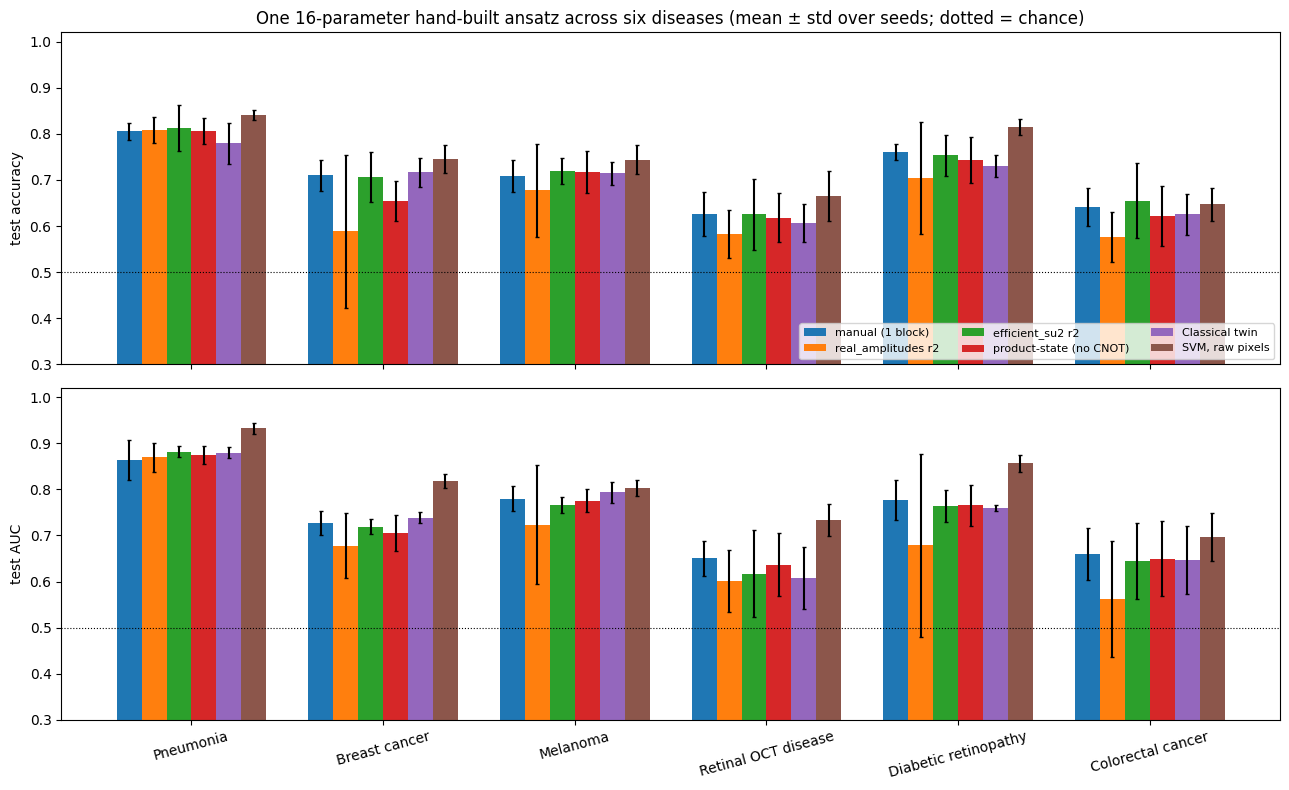

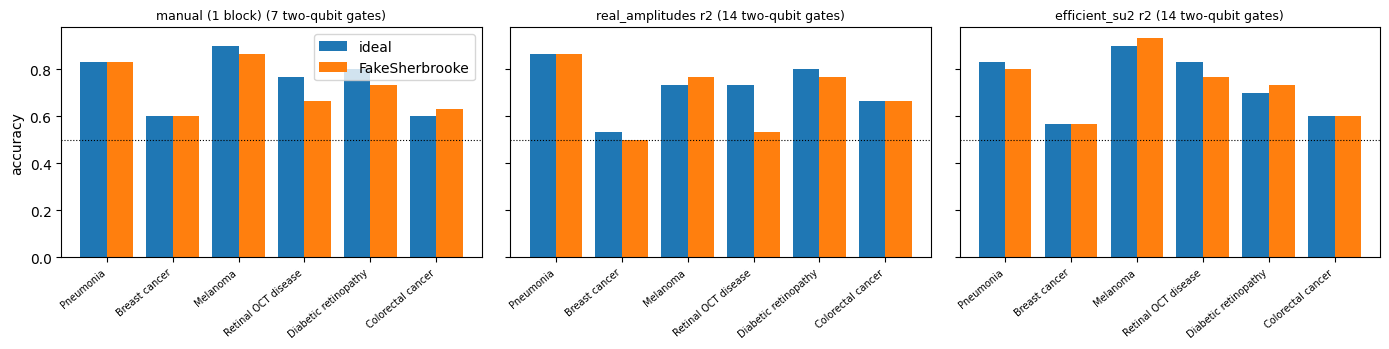

In [19]:
from scipy.stats import wilcoxon
HV = ["manual (1 block)", "manual (2 blocks)", "manual (3 blocks)", "real_amplitudes r2", "efficient_su2 r2", "product-state (no CNOT)"]
order = [t["name"] for t in TASKS]
long = pd.concat([df_main.rename(columns={"design": "model"})[["dataset", "model", "seed", "acc", "f1", "auc"]],
                  df_cls[["dataset", "model", "seed", "acc", "f1", "auc"]]])
tabA = long.groupby(["dataset", "model"], sort=False).agg(acc=("acc", "mean"), acc_std=("acc", "std"), f1=("f1", "mean"), auc=("auc", "mean")).round(3)
tabA.to_csv("hvqc_multi_tableA.csv"); display(tabA.loc[order])

def acc_of(d, m): return long[(long.dataset == d) & (long.model == m)].sort_values("seed").acc.values
rows = []
for d in order:
    a, b = acc_of(d, "manual (1 block)"), acc_of(d, "Classical twin"); sd_ = max(a.std(ddof=1) if len(a) > 1 else 0, b.std(ddof=1) if len(b) > 1 else 0)
    diff = a.mean() - b.mean()
    rows.append(dict(dataset=d, manual=round(a.mean(), 3), classical_twin=round(b.mean(), 3), diff=round(diff, 3), seed_std=round(sd_, 3),
                     verdict="HVQC better" if diff > sd_ else "classical better" if -diff > sd_ else "within noise"))
tabB = pd.DataFrame(rows); tabB.to_csv("hvqc_multi_tableB.csv"); print("Table B — manual HVQC vs classical twin"); display(tabB)

rows = []; allpairs = {"real_amplitudes r2": [], "efficient_su2 r2": []}
for other in allpairs:
    wl = {"win": 0, "tie": 0, "loss": 0}
    for d in order:
        a, b = acc_of(d, "manual (1 block)"), acc_of(d, other); s_ = max(a.std(ddof=1) if len(a) > 1 else 0, b.std(ddof=1) if len(b) > 1 else 0); diff = a.mean() - b.mean()
        wl["win" if diff > s_ else "loss" if -diff > s_ else "tie"] += 1; allpairs[other] += list(a - b)
    try: p = wilcoxon(allpairs[other]).pvalue
    except ValueError: p = float("nan")
    rows.append(dict(vs=other, **wl, mean_acc_diff=round(float(np.mean(allpairs[other])), 4), wilcoxon_p=round(float(p), 4)))
tabC = pd.DataFrame(rows); tabC.to_csv("hvqc_multi_tableC.csv"); print("Table C — manual (16 params, 7 CNOTs) vs library ansätze across datasets"); display(tabC)

key = ["manual (1 block)", "real_amplitudes r2", "efficient_su2 r2", "product-state (no CNOT)", "Classical twin", "SVM, raw pixels"]
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
w = 0.13
for k, (col, lab) in enumerate([("acc", "test accuracy"), ("auc", "test AUC")]):
    for j, m in enumerate(key):
        g = long[long.model == m].groupby("dataset")[col].agg(["mean", "std"]).loc[order]
        ax[k].bar(np.arange(len(order)) + (j - 2.5) * w, g["mean"], w, yerr=g["std"].fillna(0), label=m, capsize=1.5)
    ax[k].axhline(0.5, ls=":", c="k", lw=0.8); ax[k].set_ylabel(lab); ax[k].set_ylim(0.3, 1.02)
ax[0].legend(ncol=3, fontsize=8, loc="lower right"); ax[1].set_xticks(range(len(order))); ax[1].set_xticklabels(order, rotation=15)
ax[0].set_title("One 16-parameter hand-built ansatz across six diseases (mean ± std over seeds; dotted = chance)")
plt.tight_layout(); plt.savefig("hvqc_multi_results.png", dpi=150); plt.show()

if len(df_noise):
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
    for a, name in zip(ax, ["manual (1 block)", "real_amplitudes r2", "efficient_su2 r2"]):
        d = df_noise[df_noise.design == name].set_index("dataset").loc[order]
        a.bar(np.arange(len(order)) - 0.2, d.ideal_acc, 0.4, label="ideal"); a.bar(np.arange(len(order)) + 0.2, d.noisy_acc, 0.4, label="FakeSherbrooke")
        a.set_title(f"{name} ({int(d.two_qubit_gates.iloc[0])} two-qubit gates)", fontsize=9); a.set_xticks(range(len(order))); a.set_xticklabels(order, rotation=40, ha="right", fontsize=7); a.axhline(0.5, ls=":", c="k", lw=0.8)
    ax[0].legend(); ax[0].set_ylabel("accuracy"); plt.tight_layout(); plt.savefig("hvqc_multi_noise.png", dpi=150); plt.show()

In [20]:
lines = [f"RESULTS (auto-generated; {len(SEEDS)} seeds, N_TRAIN={N_TRAIN}, N_TEST<={N_TEST} balanced, MedMNIST 28x28, 8 qubits)", ""]
for d in order:
    r = tabB[tabB.dataset == d].iloc[0]
    lines.append(f"* {d}: manual HVQC {r.manual:.3f} vs classical twin {r.classical_twin:.3f} ({r.verdict}; seed std {r.seed_std:.3f}).")
lines += ["", "Manual (16 params, 7 CNOTs) vs library ansätze (win/tie/loss over datasets, tie = within one std):"]
lines += [f"* vs {r.vs}: {r.win}/{r.tie}/{r.loss}, mean accuracy difference {r.mean_acc_diff:+.4f}, Wilcoxon p = {r.wilcoxon_p} (exploratory)." for r in tabC.itertuples()]
if len(df_noise):
    n = df_noise.groupby("design")[["ideal_acc", "noisy_acc", "two_qubit_gates"]].mean().round(3)
    lines += ["", "FakeSherbrooke (mean over datasets): " + "; ".join(f"{k}: ideal {v.ideal_acc:.3f} -> noisy {v.noisy_acc:.3f} ({int(v.two_qubit_gates)} two-qubit gates)" for k, v in n.iterrows()) + "."]
lines += ["", f"Hardware: {hw_result if hw_result else 'not run'}.", "",
          "HOW TO READ IT: differences under ~1 std are noise. Low accuracy on hard tasks (melanoma, retinopathy) at 28x28 with 8 PCA components is mostly an input-bottleneck effect - check the classical twin on the same row. The claim the study supports is competitiveness with fewer parameters/gates plus interpretability, not quantum advantage."]
txt = "\n".join(lines); print(txt); open("hvqc_multi_results.txt", "w").write(txt)

RESULTS (auto-generated; 5 seeds, N_TRAIN=200, N_TEST<=200 balanced, MedMNIST 28x28, 8 qubits)

* Pneumonia: manual HVQC 0.805 vs classical twin 0.779 (within noise; seed std 0.044).
* Breast cancer: manual HVQC 0.710 vs classical twin 0.717 (within noise; seed std 0.034).
* Melanoma: manual HVQC 0.709 vs classical twin 0.714 (within noise; seed std 0.035).
* Retinal OCT disease: manual HVQC 0.626 vs classical twin 0.606 (within noise; seed std 0.048).
* Diabetic retinopathy: manual HVQC 0.760 vs classical twin 0.730 (HVQC better; seed std 0.025).
* Colorectal cancer: manual HVQC 0.641 vs classical twin 0.625 (within noise; seed std 0.045).

Manual (16 params, 7 CNOTs) vs library ansätze (win/tie/loss over datasets, tie = within one std):
* vs real_amplitudes r2: 1/5/0, mean accuracy difference +0.0524, Wilcoxon p = 0.0103 (exploratory).
* vs efficient_su2 r2: 0/6/0, mean accuracy difference -0.0033, Wilcoxon p = 0.4871 (exploratory).

FakeSherbrooke (mean over datasets): efficient_su2

1717

## 13. What to say about it (reviewer checklist)
* **Generality:** Tables A-C and the figure show whether the 16-parameter ansatz holds up across six diseases / four imaging types, not one dataset.
* **Does the circuit add anything?** Table B against the classical twin, per dataset. A "within noise" verdict is an honest, reportable result.
* **Entanglement and depth:** compare "product-state (no CNOT)" and the 1/2/3-block rows in the Section 8 tables.
* **Barren plateaus (Q10), shots (Q9), NISQ gap (§3.5):** Section 5, 10a and 10b.
* **Honest limits:** tiny balanced subsets (some test sets only a few dozen images), 28x28 inputs, 8 PCA components, untuned hyperparameters, binary tasks that I defined (not MedMNIST's original multi-class tasks), simulator-only unless Section 11 is run, and a 25.8k-parameter CNN beside a 16-parameter circuit. Do not claim quantum advantage or clinical value.
* **Literature:** BloodMNIST VQC-EfficientNet (96.58%) is a different task and scale: context, not a like-for-like target.